In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carga de datos

In [17]:
df_casas_entrenamiento = pd.read_csv('https://raw.githubusercontent.com/MartinDido100/ciencia-de-datos/refs/heads/main/primer_parcial/datasets/casas_entrenamiento.csv')
df_casas_entrenamiento.head(5)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
0,vz/dYJl3t6dAAhuCMR9pFg==,Propiedad,2020-03-21,9999-12-31,2020-03-21,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,4.0,3.0,2.0,NaN,NaN,NaN,"Casa en Venta en Primera sección, Tigre U$S 19...",no paga
1,7WuevfRjW78WomnkinRSAA==,Propiedad,2019-05-22,9999-12-31,2019-05-22,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,3.0,NaN,1.0,120.0,105.0,Mensual,Casa en venta en Tigre con dos dormitorios y j...,no paga
2,zZlOOuCPY//CPsAuwgfICA==,Propiedad,2019-10-13,2019-10-28,2019-10-13,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,...,NaN,NaN,NaN,2.0,2.0,230.0,230.0,NaN,Casa de 3 ambientes en Venta en Villa crespo,no paga
3,dZmdfoiNyUCOgDbRXIuPCg==,Propiedad,2020-01-10,9999-12-31,2020-01-10,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,...,NaN,NaN,4.0,NaN,1.0,63.0,63.0,Mensual,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz,no paga
4,nt8/Rc6J4m3all/FkfX0gQ==,Propiedad,2019-04-03,2020-04-16,2019-04-03,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,NaN,NaN,8.0,6.0,NaN,NaN,NaN,NaN,Inmueble en block en Venta. 8 Amb. 6 Dor,no paga


In [18]:
df_casas_predecir = pd.read_csv('https://raw.githubusercontent.com/MartinDido100/ciencia-de-datos/refs/heads/main/primer_parcial/datasets/casas_predecir.csv')
df_casas_predecir.head(5)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
0,YNsMDAiJDbpSUbOHt+rSvQ==,Propiedad,2020-04-04,9999-12-31,2020-04-04,-34.596478,-58.584692,Argentina,Bs.As. G.B.A. Zona Oeste,Tres de Febrero,...,NaN,NaN,4.0,3.0,3.0,NaN,NaN,NaN,Triplex en Venta en Ciudad Jardin,no paga
1,BoKiYfTPcZ8LpdTSuS7PVA==,Propiedad,2019-07-04,9999-12-31,2019-07-04,-34.497770,-58.714840,Argentina,Bs.As. G.B.A. Zona Norte,Malvinas Argentinas,...,NaN,NaN,4.0,NaN,1.0,120.0,120.0,Mensual,Casa - Grand Bourg,no paga
2,sUU+KBSqGEYMNmENHFLomA==,Propiedad,2019-11-29,9999-12-31,2019-11-29,-34.741347,-58.399689,Argentina,Bs.As. G.B.A. Zona Sur,Lomas de Zamora,...,NaN,NaN,4.0,0.0,1.0,NaN,NaN,NaN,"Casa en Venta en Banfield oeste, banfield U$...",no paga
3,4aFQ09OzllVbPl57kB7oCQ==,Propiedad,2019-09-03,9999-12-31,2019-09-03,-34.623179,-58.519398,Argentina,Capital Federal,Versalles,...,NaN,NaN,4.0,NaN,2.0,230.0,126.0,Mensual,Casa 4 ambientes Reciclada a nueva en Impecabl...,no paga
4,bczZnJ0pADQI2XNR4ivWvg==,Propiedad,2019-04-30,9999-12-31,2019-04-30,-37.977329,-57.557187,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,NaN,NaN,3.0,2.0,1.0,150.0,100.0,NaN,Chalet en Venta. 3 Amb. 2 Dor. 150 M2. 100 M2 Cub,no paga


`id` va a ser el índice (sugerencia del enunciado), pero no lo ponemos acá: lo hace la función `id_como_indice` al principio del pipeline, al final del notebook. Hasta ese punto `id` sigue siendo una columna, y las celdas de revisión y limpieza lo tratan como tal.

¿Por qué índice y no columna? El id no es una característica de la casa. Es un código al azar que no dice nada sobre si paga comisión. Si queda como columna, es fácil que termine entrando al modelo sin querer, por ejemplo al hacer df.drop(columns='paga_comision') para armar X. Tiene un valor distinto por fila, así que solo aporta ruido. Y con one-hot encoding generaría una columna nueva por casa. Como índice queda fuera de X sin que tengas que acordarte de sacarlo.
Cada predicción sigue atada a su casa. El índice acompaña a cada fila cuando filtrás, separás en train/test o eliminás nulos. Al final, armar el entregable es directo:
pred = modelo.predict(X_predecir)
ids_paga = X_predecir.index[pred == 'paga']
pd.DataFrame(index=ids_paga).to_csv('casas_entrega.csv')
   Sin el índice, después de filtrar filas tendrías que volver a emparejar a mano cada predicción con su id, y ahí aparecen los errores.
Permite controlar los errores que el enunciado advierte. El PDF pide verificar que los ids del entregable pertenezcan a casas_predecir.csv y no a los de entrenamiento:
assert ids_paga.isin(df_casas_predecir.index).all()
assert not ids_paga.isin(df_casas_entrenamiento.index).any()

## Trampas de estructura (1/3): columnas de cada archivo

**Por qué:** el modelo se entrena con las columnas de `casas_entrenamiento` y después se aplica a `casas_predecir`. Si un archivo tiene una columna que el otro no, o la misma columna con otro tipo de dato, el modelo falla al predecir o usa información que no va a estar disponible.

**Qué hace:** arma una tabla con todas las columnas de los dos archivos, una al lado de la otra, con el tipo de dato en cada uno y si coinciden. Debajo lista las columnas que están en un solo archivo.

In [6]:
# Comparación de columnas entre los dos archivos

# Si ya se corrió set_index("id"), id pasó al índice: trabajamos sobre una copia con id como columna.
# Así la celda da lo mismo sin importar el orden en que se ejecutó el notebook (no modifica los originales).
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# Tabla con todas las columnas de ambos datasets, una al lado de la otra.
# Si una columna falta en un archivo, su tipo aparece como NaN en esa fila.
comparacion_columnas = pd.DataFrame({
    'casas_entrenamiento': tr.dtypes,
    'casas_predecir': pr.dtypes,
})
comparacion_columnas['tipos_iguales'] = comparacion_columnas['casas_entrenamiento'] == comparacion_columnas['casas_predecir']
print("Cantidad de columnas -> entrenamiento:", tr.shape[1], "| predecir:", pr.shape[1])
display(comparacion_columnas)

# Columnas presentes en un archivo y no en el otro
cols_tr, cols_pr = set(tr.columns), set(pr.columns)
print("Solo en entrenamiento:", sorted(cols_tr - cols_pr))
print("Solo en predecir:     ", sorted(cols_pr - cols_tr))

Cantidad de columnas -> entrenamiento: 21 | predecir: 21


,casas_entrenamiento,casas_predecir,tipos_iguales
id,object,object,True
ad_type,object,object,True
start_date,object,object,True
end_date,object,object,True
created_on,object,object,True
lat,float64,float64,True
lon,float64,float64,True
l1,object,object,True
l2,object,object,True
l3,object,object,True


Solo en entrenamiento: []
Solo en predecir:      []


## Trampas de estructura (2/3): ids duplicados y compartidos

**Por qué:** `id` va a ser el índice y es lo único que se entrega en `casas_entrega.csv`. Si un id se repite dentro de un archivo, una misma predicción quedaría asociada a dos casas. Si un id aparece en los dos archivos, se podría terminar entregando un id de entrenamiento, que es justo el error que advierte el enunciado.

**Qué hace:** cuenta filas, ids únicos e ids repetidos en cada archivo, y calcula cuántos ids comparten casas_entrenamiento y casas_predecir. Al final, tres `assert` frenan el notebook si alguna de estas condiciones no se cumple, para no seguir trabajando sobre una base rota.

In [7]:
# Ids duplicados dentro de cada archivo y compartidos entre ambos
# Si ya se corrió set_index("id"), trabajamos sobre una copia con id como columna (no modifica los originales)
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

datasets = {'casas_entrenamiento': tr, 'casas_predecir': pr}
for nombre, df in datasets.items():
    print(f"[{nombre}] filas: {len(df)} | ids únicos: {df['id'].nunique()} | ids duplicados: {df['id'].duplicated().sum()}")
ids_compartidos = set(tr['id']) & set(pr['id'])
print("Ids compartidos entre entrenamiento y predecir:", len(ids_compartidos))

# Verificaciones que el resto del notebook da por hechas
assert tr['id'].is_unique, "Hay ids repetidos en entrenamiento"
assert pr['id'].is_unique, "Hay ids repetidos en predecir"
assert len(ids_compartidos) == 0, "Hay ids compartidos entre entrenamiento y predecir"

[casas_entrenamiento] filas: 61577 | ids únicos: 61577 | ids duplicados: 0
[casas_predecir] filas: 41054 | ids únicos: 41054 | ids duplicados: 0
Ids compartidos entre entrenamiento y predecir: 0


## Trampas de estructura (3/3): filas duplicadas

**Por qué:** una misma propiedad puede estar publicada varias veces con distinto id (avisos re-publicados). Eso trae tres problemas:
- Si una copia queda en train y otra en test, el modelo "reconoce" la casa en vez de predecirla y la ganancia estimada sale optimista.
- Si las copias tienen etiquetas distintas, hay ruido en la variable objetivo.
- Si una casa de predecir es idéntica a una de entrenamiento, su etiqueta ya se conoce.

**Qué hace:** en cada archivo cuenta los duplicados exactos (todas las columnas) y los duplicados ignorando `id` y `paga_comision` (en predecir esa columna es relleno). En entrenamiento cuenta cuántos grupos de casas idénticas tienen etiquetas contradictorias. Por último, cruza los dos archivos para contar cuántas filas de predecir son idénticas a alguna de entrenamiento.

In [8]:
# Filas duplicadas
# Si ya se corrió set_index("id"), trabajamos sobre una copia con id como columna (no modifica los originales)
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# - exactas (todas las columnas, incluido id)
# - "misma propiedad con otro id": se ignoran id y paga_comision (en predecir es relleno)
features = [c for c in tr.columns if c not in ('id', 'paga_comision')]
for nombre, df in {'casas_entrenamiento': tr, 'casas_predecir': pr}.items():
    print(f"[{nombre}] duplicados exactos: {df.duplicated().sum()} | "
          f"duplicados ignorando id: {df.duplicated(subset=features).sum()}")

# En entrenamiento: ¿hay duplicados con etiquetas distintas? (misma casa, una 'paga' y otra 'no paga')
etiquetas_por_casa = tr.groupby(features, dropna=False)['paga_comision'].nunique()
print("\nGrupos de duplicados en entrenamiento con etiqueta contradictoria:", (etiquetas_por_casa > 1).sum())

# Entre archivos: filas de predecir idénticas a alguna de entrenamiento (sin contar id ni target)
cruce = pr[features].merge(tr[features].drop_duplicates(), how='inner', on=features)
print("Filas de predecir idénticas a una de entrenamiento:", len(cruce))

[casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867
[casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425

Grupos de duplicados en entrenamiento con etiqueta contradictoria: 16
Filas de predecir idénticas a una de entrenamiento: 907


[casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867    -> Hay que eliminar los duplicados del set de entrenamiento porque producen overfitting

[casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425         -> No hace falta eliminarlos ya que pueden ser duplicados reales

Grupos de duplicados en entrenamiento con etiqueta contradictoria: 16         -> Los 16 grupos (33 filas en total) hay que eliminarlos ya que presentan contradicción para el modelo

Filas de predecir idénticas a una de entrenamiento: 907                       -> Eliminamos las filas del set de entrenamiento ya que el dataset de producción debe predecirse completo. Así también evitamos data leakage

## Limpieza de duplicados (1/3): casas con etiqueta contradictoria (16 grupos, 33 filas)

**Por qué:** hay propiedades idénticas en todas sus columnas (salvo `id`) que en una fila figuran como `paga` y en otra como `no paga`. Con los mismos datos de entrada, el modelo recibe dos respuestas opuestas: es ruido que no puede aprender. Como no hay forma de saber cuál etiqueta es la correcta, se eliminan **todas** las filas de esos grupos, sin elegir una. Este paso va antes de quitar los duplicados: si se deduplicara primero, cada grupo quedaría en una sola fila con una etiqueta elegida al azar y la contradicción ya no se vería.

**Qué hace:** calcula una "huella" de cada fila a partir de todas las columnas menos `id` y `paga_comision` (filas idénticas tienen la misma huella). Cuenta cuántas etiquetas distintas tiene cada huella y elimina del entrenamiento las filas cuya huella tiene más de una.

In [9]:
# Columnas que describen la casa: todas menos id y el target
# (funciona tanto si id es columna como si ya es el índice)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

# Huella de cada fila: filas idénticas en 'features' tienen el mismo número (los NaN también se comparan bien)
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)

# Para cada fila, cuántas etiquetas distintas tiene su grupo de casas idénticas
etiquetas_en_grupo = df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].transform('nunique')
contradictorias = etiquetas_en_grupo > 1

filas_antes = len(df_casas_entrenamiento)
print("Grupos con etiqueta contradictoria:", huella_tr[contradictorias].nunique())
print("Filas a eliminar (todas las de esos grupos):", contradictorias.sum())

df_casas_entrenamiento = df_casas_entrenamiento[~contradictorias]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: ya no queda ninguna casa con dos etiquetas distintas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert (df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].nunique() == 1).all()

Grupos con etiqueta contradictoria: 16
Filas a eliminar (todas las de esos grupos): 33
Entrenamiento: 61577 -> 61544 filas


## Limpieza de duplicados (2/3): duplicados dentro del entrenamiento

**Por qué:** una misma casa publicada varias veces con distinto `id` pesa doble en el entrenamiento, y al separar train/test una copia puede quedar de cada lado. En ese caso el modelo "reconoce" la casa en vez de predecirla, sobreajusta y la ganancia estimada en test sale más alta de lo que va a ser con casas nuevas. En `casas_predecir` no se eliminan: hay que entregar una predicción para cada `id`.

**Qué hace:** elimina las filas del entrenamiento que son idénticas a otra en todas las columnas menos `id` (la etiqueta ya coincide, porque las contradictorias se quitaron en el paso anterior). Conserva la primera aparición de cada casa.

In [10]:
# Duplicados de la misma casa con distinto id (se ignora id; la etiqueta ya es consistente)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

filas_antes = len(df_casas_entrenamiento)
print("Duplicados a eliminar:", df_casas_entrenamiento.duplicated(subset=features).sum())

# keep='first': de cada grupo de casas idénticas queda la primera fila
df_casas_entrenamiento = df_casas_entrenamiento.drop_duplicates(subset=features, keep='first')
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: no quedan casas repetidas en el entrenamiento
assert not df_casas_entrenamiento.duplicated(subset=features).any()

Duplicados a eliminar: 850
Entrenamiento: 61544 -> 60694 filas


## Limpieza de duplicados (3/3): casas de entrenamiento que también están en predecir

**Por qué:** hay casas de `casas_predecir` idénticas a casas del entrenamiento. `casas_predecir` es el dataset de producción y se predice completo, así que de ahí no se puede sacar nada; las coincidencias se quitan del entrenamiento. Así los dos conjuntos quedan disjuntos: el modelo se entrena y se valida solo con casas que no va a tener que predecir, y su rendimiento estimado refleja lo que va a pasar con casas nuevas, no con casas que ya vio.

**Qué hace:** calcula la huella (todas las columnas menos `id` y `paga_comision`) de cada fila de los dos archivos y elimina del entrenamiento las filas cuya huella aparece en `casas_predecir`. `casas_predecir` no se modifica.

In [11]:
# Casas del entrenamiento idénticas a alguna de predecir (sin contar id ni target)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
huella_pr = pd.util.hash_pandas_object(df_casas_predecir[features], index=False)
en_predecir = huella_tr.isin(huella_pr)

filas_antes, filas_predecir = len(df_casas_entrenamiento), len(df_casas_predecir)
print("Filas de entrenamiento que también están en predecir:", en_predecir.sum())
print("Filas de predecir afectadas (se mantienen):", huella_pr.isin(huella_tr).sum())

df_casas_entrenamiento = df_casas_entrenamiento[~en_predecir]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificaciones: los conjuntos quedaron disjuntos y predecir no perdió filas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert not huella_tr.isin(huella_pr).any()
assert len(df_casas_predecir) == filas_predecir

Filas de entrenamiento que también están en predecir: 708
Filas de predecir afectadas (se mantienen): 902
Entrenamiento: 60694 -> 59986 filas


# Análisis exploratorio
Sobre el entrenamiento ya limpio: son los mismos datos con los que se entrena el modelo.

## Variable target: `paga_comision`

paga_comision
no paga    54741
paga        6836
Name: count, dtype: int64
paga_comision
no paga    88.9
paga       11.1
Name: proportion, dtype: float64


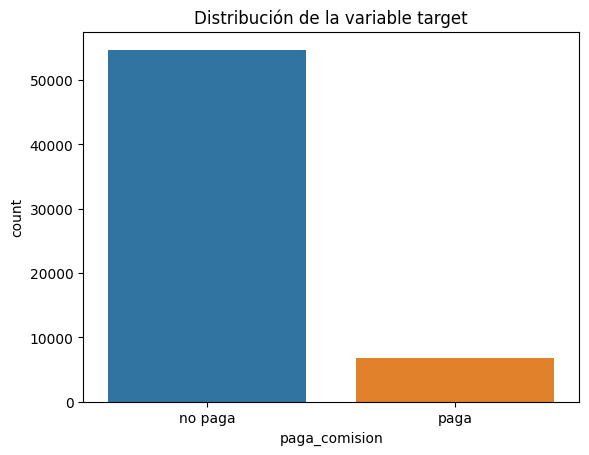

In [19]:
print( df_casas_entrenamiento.paga_comision.value_counts() )
print( (df_casas_entrenamiento.paga_comision.value_counts(normalize=True) * 100).round(2) )
sns.countplot(x='paga_comision', data=df_casas_entrenamiento, hue='paga_comision', legend=False)
plt.title('Distribución de la variable target')
plt.show()

El dataset está **desbalanceado** (~89% `no paga` vs ~11% `paga`). Un modelo que siempre diga `no paga` tendría un accuracy de casi 89% y ganancia nula, por eso hay que evaluar con la **función de ganancia** del enunciado y no solo con accuracy.

Para los gráficos trabajamos sobre una copia (`df_eda`) con el target en formato numérico (1 = paga), así el promedio de `target` por grupo es directamente la **tasa de pago de comisión**.

## ¿Los nulos dicen algo sobre el target?
Si el porcentaje de nulos de una columna es distinto entre `paga` y `no paga`, el hecho de que falte el dato es información útil (se puede crear una feature indicadora de nulo en vez de solo imputar).

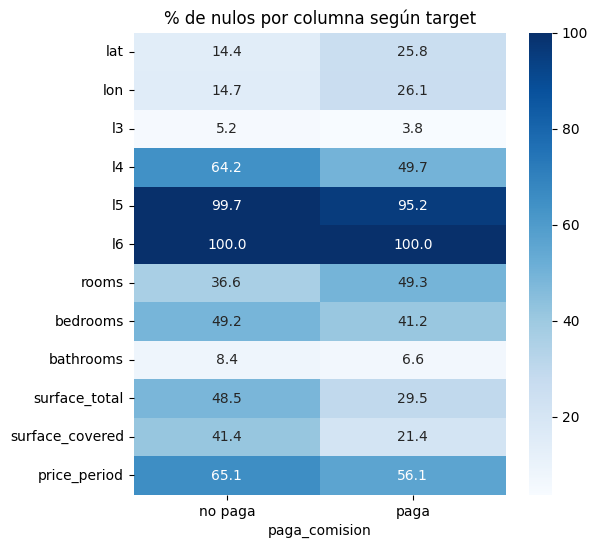

In [20]:
nulos_por_target = df_eda.drop(columns=['target']).isnull().groupby(df_eda.paga_comision).mean().T * 100
nulos_por_target = nulos_por_target[nulos_por_target.sum(axis=1) > 0]

plt.figure(figsize=(6,6))
sns.heatmap(nulos_por_target, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de nulos por columna según target')
plt.show()

## Variables numéricas
Hay valores imposibles: superficies negativas o en 0, `bedrooms` negativos o de hasta 37, superficies de 200.000 m² y casas con más superficie cubierta que total. Graficamos con escala logarítmica y recortando al percentil 99 para poder ver la forma real de las distribuciones.

In [21]:
numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']

print("Superficies <= 0:", (df_eda[['surface_total','surface_covered']] <= 0).sum().to_dict())
print("surface_covered > surface_total:", (df_eda.surface_covered > df_eda.surface_total).sum())
print("Percentil 99:")
print(df_eda[numericas].quantile(0.99))

Superficies <= 0: {'surface_total': 39, 'surface_covered': 1}
surface_covered > surface_total: 1108
Percentil 99:
rooms                10.00
bedrooms              6.00
bathrooms             6.00
surface_total      3403.04
surface_covered     748.74
Name: 0.99, dtype: float64


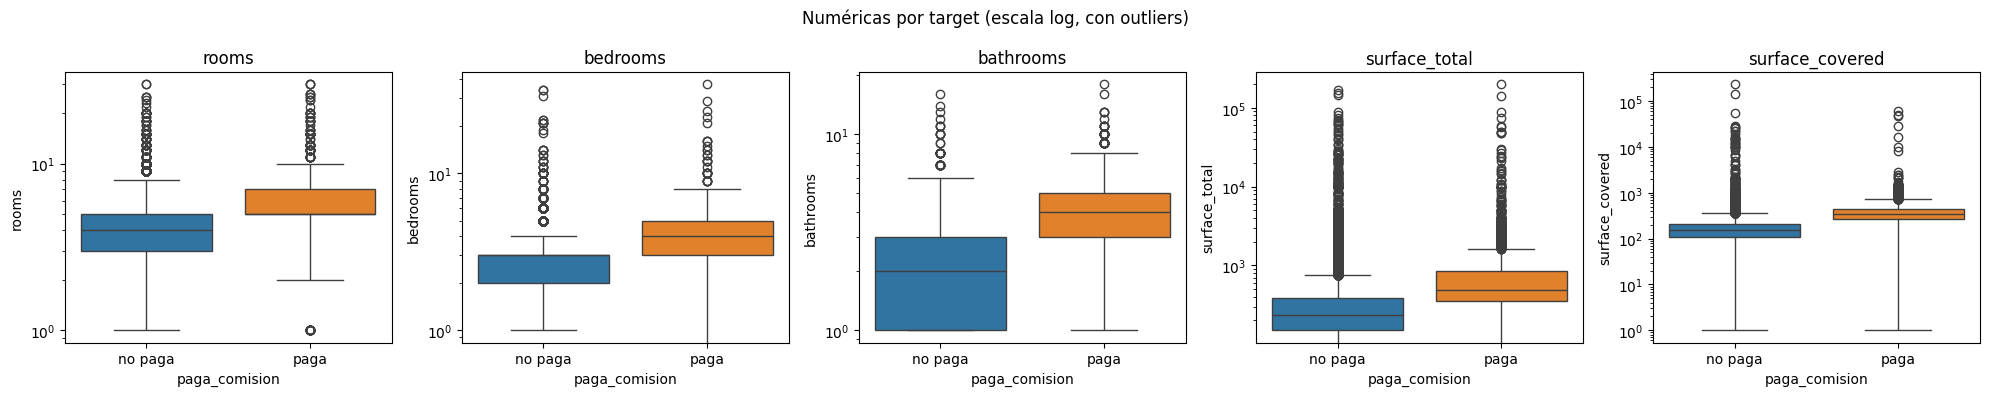

In [22]:
fig, axes = plt.subplots(1, len(numericas), figsize=(20,4))
for ax, col in zip(axes, numericas):
    sns.boxplot(x='paga_comision', y=col, data=df_eda, ax=ax, hue='paga_comision', legend=False)
    ax.set_yscale('log')
    ax.set_title(col)
plt.suptitle('Numéricas por target (escala log, con outliers)')
plt.tight_layout()
plt.show()

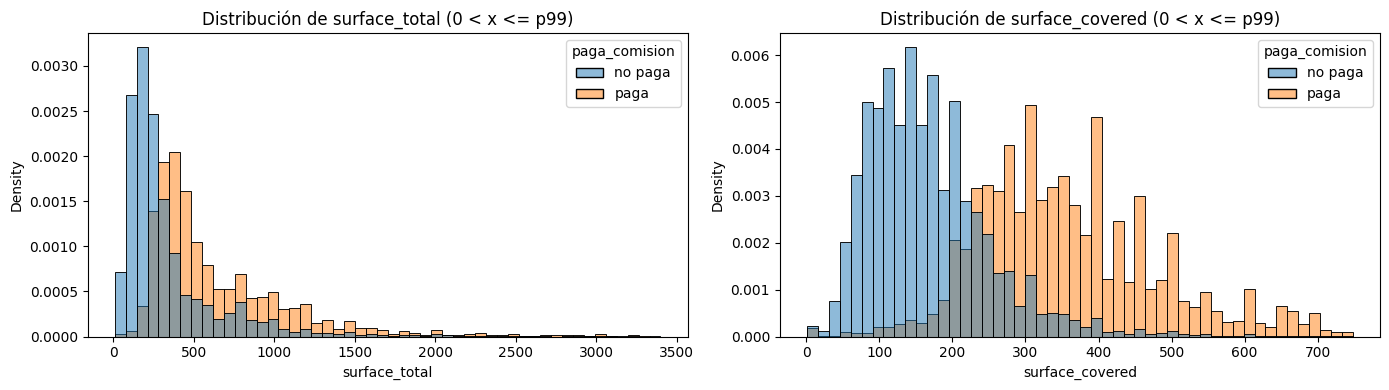

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
for ax, col in zip(axes, ['surface_total', 'surface_covered']):
    p99 = df_eda[col].quantile(0.99)
    datos = df_eda[(df_eda[col] > 0) & (df_eda[col] <= p99)]
    sns.histplot(data=datos, x=col, hue='paga_comision', bins=50, stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribución de {col} (0 < x <= p99)')
plt.tight_layout()
plt.show()

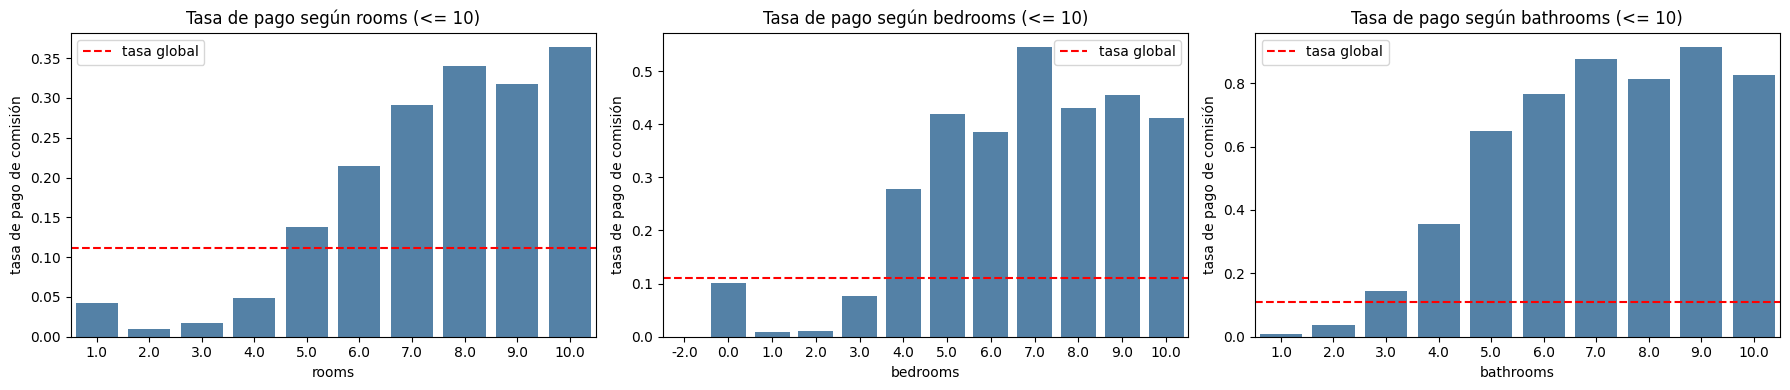

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
for ax, col in zip(axes, ['rooms', 'bedrooms', 'bathrooms']):
    datos = df_eda[df_eda[col] <= 10]
    sns.barplot(x=col, y='target', data=datos, ax=ax, color='steelblue', errorbar=None)
    ax.axhline(tasa_global, color='red', linestyle='--', label='tasa global')
    ax.set_ylabel('tasa de pago de comisión')
    ax.set_title(f'Tasa de pago según {col} (<= 10)')
    ax.legend()
plt.tight_layout()
plt.show()

## Correlación entre numéricas y target

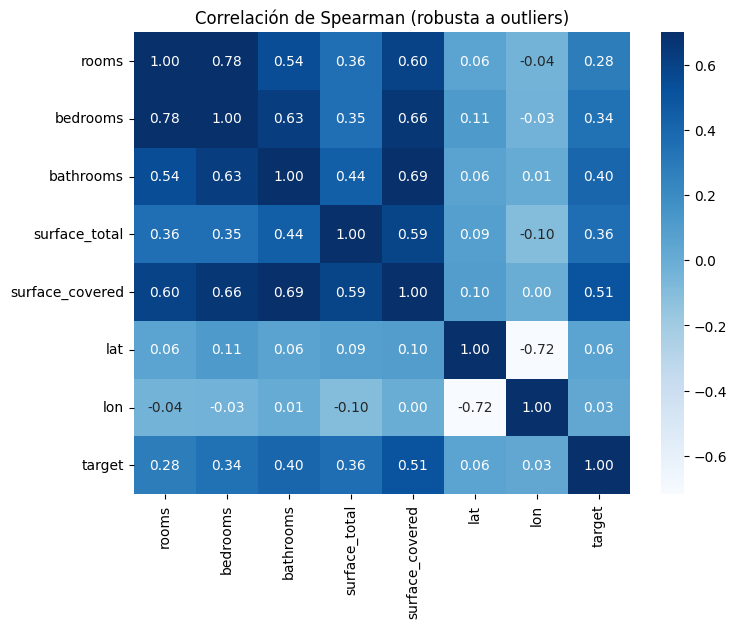

In [25]:
plt.figure(figsize=(8,6))
sns.heatmap(df_eda[numericas + ['lat', 'lon', 'target']].corr(method='spearman'), annot=True, fmt='.2f', cmap='Blues', vmax=.7)
plt.title('Correlación de Spearman (robusta a outliers)')
plt.show()

## Ubicación: país (`l1`) y provincia/región (`l2`)
`l1` (3 países) y `l2` (38 regiones) tienen pocas categorías, así que se pueden usar con one-hot. `l3` (ciudad, 559 valores) tiene alta cardinalidad y en el pipeline se usa con target encoding. `l4` y `l5` tienen muchos nulos (más de la mitad en `l4` y casi el 100% en `l5`) y quedan fuera del modelo.

l1      3
l2     38
l3    559
l4    677
l5     17
dtype: int64


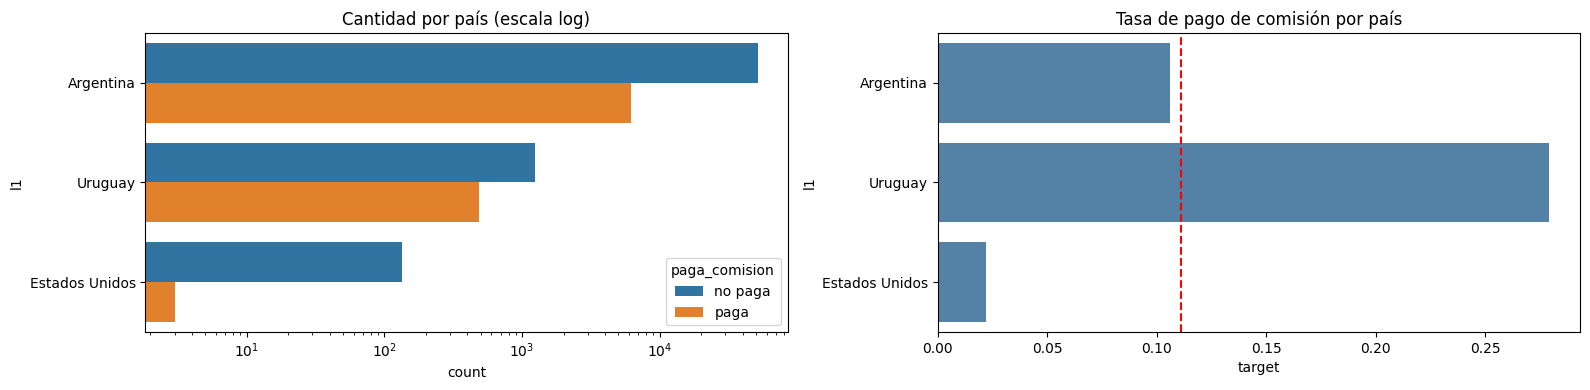

In [26]:
print(df_eda[['l1', 'l2', 'l3', 'l4', 'l5']].nunique())

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.countplot(y='l1', data=df_eda, hue='paga_comision', ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title('Cantidad por país (escala log)')
sns.barplot(y='l1', x='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axvline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago de comisión por país')
plt.tight_layout()
plt.show()

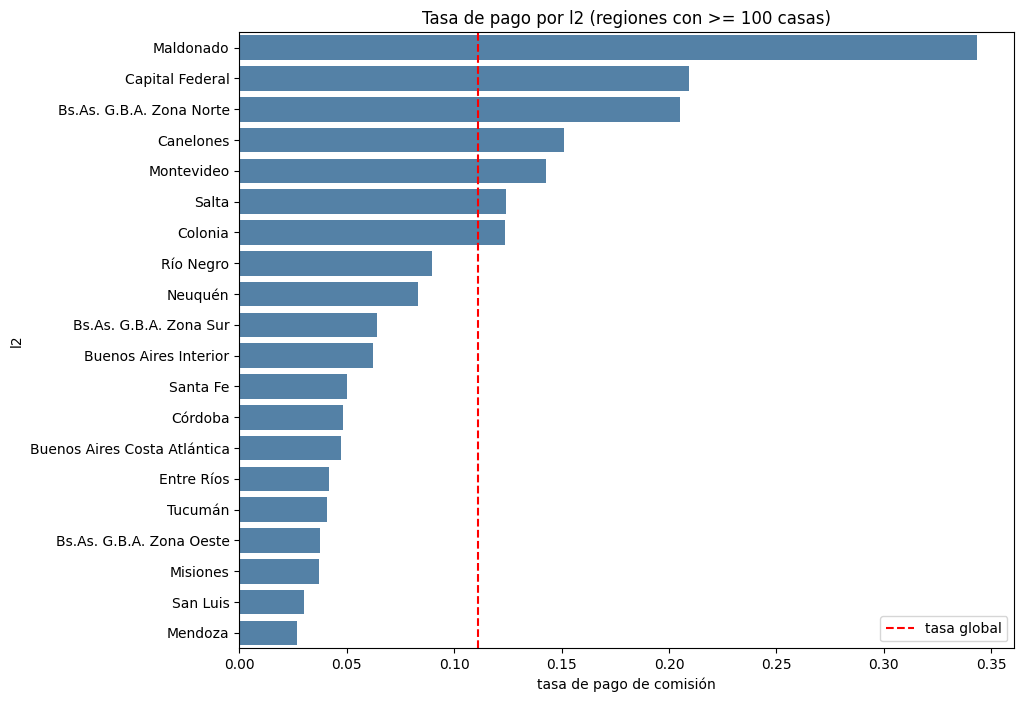

In [27]:
resumen_l2 = df_eda.groupby('l2').target.agg(cantidad='size', tasa='mean')
resumen_l2 = resumen_l2[resumen_l2.cantidad >= 100].sort_values('tasa', ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(y=resumen_l2.index, x=resumen_l2.tasa, color='steelblue')
plt.axvline(tasa_global, color='red', linestyle='--', label='tasa global')
plt.xlabel('tasa de pago de comisión')
plt.title('Tasa de pago por l2 (regiones con >= 100 casas)')
plt.legend()
plt.show()

## Coordenadas (`lat`, `lon`)
Hay coordenadas inválidas (lat = 85, lon = -180, fuera de Argentina y Uruguay). Filtramos a un rango razonable para graficar.

Coordenadas fuera de rango (sin contar nulos): 139


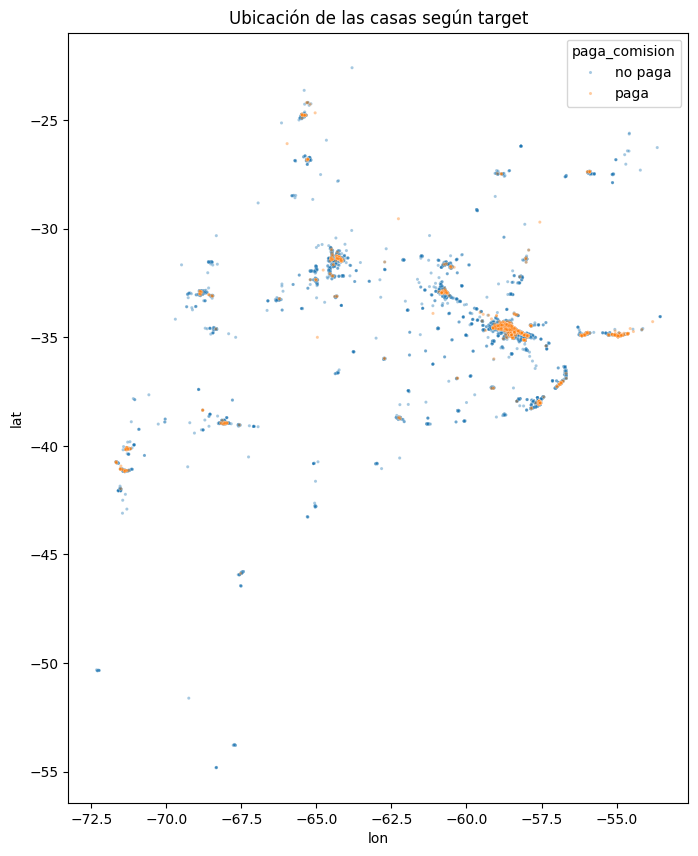

In [28]:
coord_validas = df_eda.lat.between(-56, -21) & df_eda.lon.between(-74, -52)
print("Coordenadas fuera de rango (sin contar nulos):", (~coord_validas & df_eda.lat.notna() & df_eda.lon.notna()).sum())

datos = df_eda[coord_validas].sort_values('target')  # 'paga' se dibuja arriba
plt.figure(figsize=(8,10))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=datos, s=5, alpha=0.4)
plt.title('Ubicación de las casas según target')
plt.show()

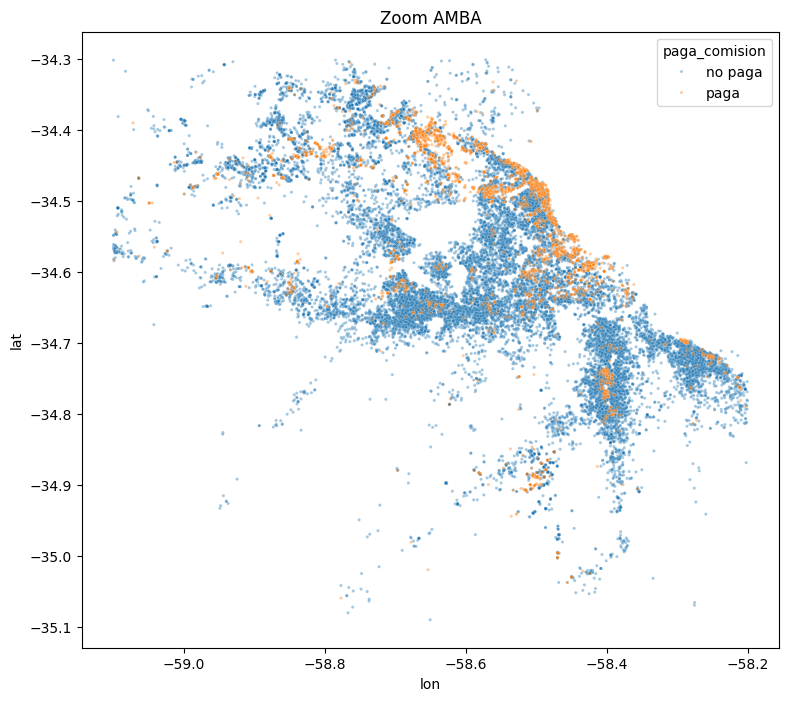

In [29]:
amba = df_eda[df_eda.lat.between(-35.1, -34.3) & df_eda.lon.between(-59.1, -58.2)].sort_values('target')
plt.figure(figsize=(9,8))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=amba, s=5, alpha=0.4)
plt.title('Zoom AMBA')
plt.show()

## `price_period` y fechas
`price_period` solo toma `Mensual` o nulo, así que funciona como una variable binaria. De las fechas extraemos información de baja dimensionalidad: mes de publicación, duración del aviso y si sigue activo (`end_date` = 9999-12-31).

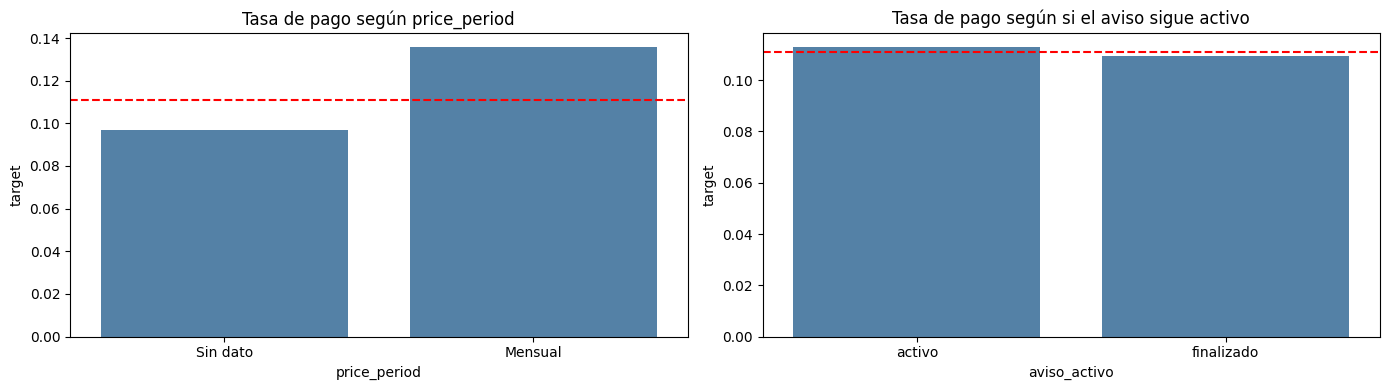

In [30]:
df_eda['price_period'] = df_eda.price_period.fillna('Sin dato')
df_eda['created_on'] = pd.to_datetime(df_eda.created_on)
df_eda['start_date'] = pd.to_datetime(df_eda.start_date)
df_eda['aviso_activo'] = (df_eda.end_date == '9999-12-31').map({True: 'activo', False: 'finalizado'})
df_eda['mes_publicacion'] = df_eda.created_on.dt.to_period('M').astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.barplot(x='price_period', y='target', data=df_eda, ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].set_title('Tasa de pago según price_period')
sns.barplot(x='aviso_activo', y='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axhline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago según si el aviso sigue activo')
plt.tight_layout()
plt.show()

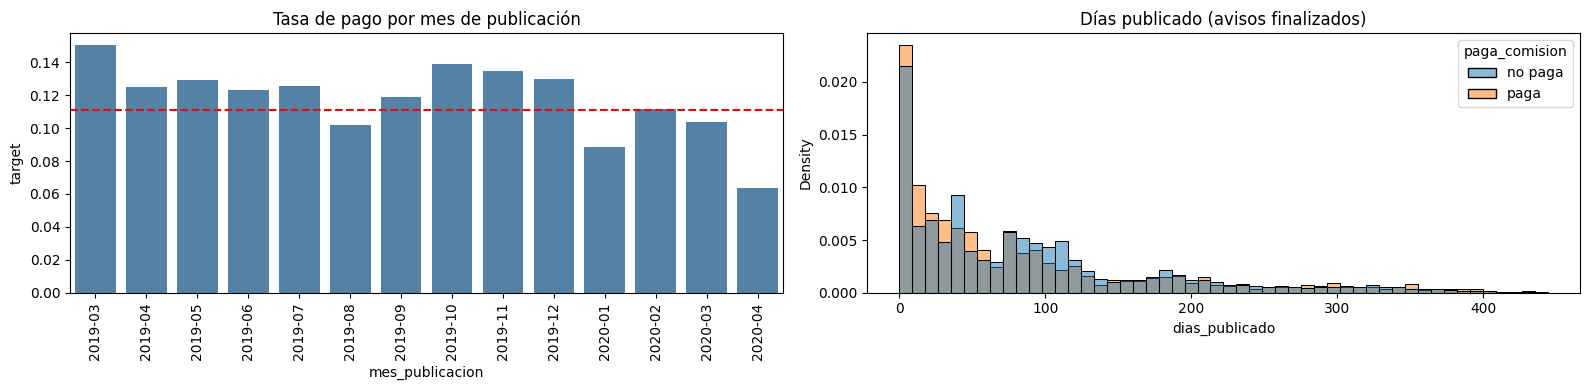

In [31]:
fin = pd.to_datetime(df_eda.end_date.where(df_eda.end_date != '9999-12-31'))
df_eda['dias_publicado'] = (fin - df_eda.start_date).dt.days

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.barplot(x='mes_publicacion', y='target', data=df_eda.sort_values('mes_publicacion'), ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Tasa de pago por mes de publicación')
sns.histplot(data=df_eda, x='dias_publicado', hue='paga_comision', bins=50, stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Días publicado (avisos finalizados)')
plt.tight_layout()
plt.show()

## Conclusiones del análisis exploratorio
Números calculados sobre el entrenamiento ya limpio (59.986 casas):

1. **Target desbalanceado** (~11% paga): evaluar con la función de ganancia, no con accuracy.
2. **Columnas sin información**: `l6` (100% nula), `ad_type` (un solo valor) y `created_on` (idéntica a `start_date`). Se eliminan.
3. **Tamaño de la casa** (`rooms`, `bedrooms`, `bathrooms`, superficies) es lo que más separa las clases: las que pagan son más grandes (mediana de superficie cubierta 350 m² contra 155 m²). Las numéricas con mayor correlación con el target son `surface_covered` (0,51) y `bathrooms` (0,40). La tasa de pago pasa del 1% con 1 baño al 65% con 5.
4. **Datos inválidos**: superficies negativas o en 0, `surface_covered > surface_total` (1.108 casas), `bedrooms` negativos o extremos y superficies de hasta 235.000 m². En el pipeline se pasan a NaN (no se borran filas, porque en predecir hay que predecir todas) y la superficie cubierta se recorta al percentil 99,9.
5. **Los nulos son informativos**: las superficies faltan más en las que no pagan (48,5% contra 29,5% en `surface_total`) y `rooms` falta más en las que pagan (49,3% contra 36,6%). Por eso en el pipeline se crean indicadores de nulo antes de imputar.
6. **Ubicación**: las tasas por región son muy distintas. Maldonado (34%), Capital Federal (21%) y Zona Norte (21%) están muy por encima de la media; Mendoza, San Luis y Zona Oeste rondan el 3%, y Estados Unidos el 2%. `l1` y `l2` van con one-hot, `l3` con target encoding, y `l4` y `l5` se descartan por la cantidad de nulos.
7. **Coordenadas**: 139 casas con coordenadas fuera de rango y correlación casi nula con el target (0,06 y 0,03). Lo que aportan ya lo cubre `l2`/`l3`, así que `lat` y `lon` se descartan.
8. **`price_period` y fechas**: diferencias chicas (13,6% de pago con `Mensual` contra 9,7% sin dato; 11,3% con el aviso activo contra 10,9% finalizado). Quedan fuera del modelo base.
9. **`title`**: aunque es texto libre, es la fuente de las features más fuertes. De ahí el pipeline extrae el precio en dólares, el tipo de propiedad (dúplex, PH, departamento, chalet) y palabras como piscina, country o barrio cerrado.

Próximo paso: el pipeline de preprocesamiento, que aplica estas decisiones.

# Preprocesamiento (pipeline)
Aplica las decisiones del análisis exploratorio. Al final se exportan los dos datasets procesados para inspeccionarlos.

In [32]:
import re
import unicodedata
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, TargetEncoder

# ============================================================================
# 0) FUERA DEL PIPELINE: id como índice y separación de X / y.
#    El target nunca va dentro de las predictoras (error común), y el Pipeline
#    estándar no puede eliminar filas, por eso la limpieza de duplicados quedó antes.
# ============================================================================
def id_como_indice(df):
    # id no describe la casa, pero lo necesitamos para el entregable
    return df.set_index('id') if 'id' in df.columns else df

entrenamiento = id_como_indice(df_casas_entrenamiento)
y = (entrenamiento['paga_comision'] == 'paga').astype(int)                    # 1 = paga, 0 = no paga
X = entrenamiento.drop(columns=['paga_comision'])
X_predecir = id_como_indice(df_casas_predecir).drop(columns=['paga_comision'])  # en predecir es relleno


# ============================================================================
# 1) PASOS "STATELESS" -> FunctionTransformer
#    Reglas fijas que no aprenden nada de los datos: dan lo mismo en train,
#    test y predecir, así que no pueden generar fuga.
# ============================================================================

# ad_type: un solo valor | l6: 100% vacía | created_on: idéntica a start_date
# lat/lon, l4, l5, price_period: decisión del análisis
# start_date/end_date: casi no cambian la tasa de pago (quedan fuera del modelo base)
COLUMNAS_A_ELIMINAR = ['ad_type', 'l6', 'created_on', 'lat', 'lon', 'l4', 'l5',
                       'price_period', 'start_date', 'end_date']

def eliminar_columnas(X):
    return X.drop(columns=COLUMNAS_A_ELIMINAR)


def invalidos_a_nan(X):
    # Valores imposibles -> NaN (no se borran filas: en predecir hay que predecir todas)
    X = X.copy()
    # bedrooms: 0 es un faltante disfrazado (casas de US$ 550.000 con 0 dormitorios); negativos y > 15 son imposibles
    X.loc[(X['bedrooms'] <= 0) | (X['bedrooms'] > 15), 'bedrooms'] = np.nan
    # bathrooms: más de 8 baños se considera error de carga
    X.loc[X['bathrooms'] > 8, 'bathrooms'] = np.nan
    # superficies: 0, negativas o menores a 20 m² no son posibles para una casa
    X.loc[X['surface_total'] < 20, 'surface_total'] = np.nan
    X.loc[X['surface_covered'] < 20, 'surface_covered'] = np.nan
    # cubierta > total es inconsistente: se descarta la total (la cubierta tiene menos errores)
    X.loc[X['surface_covered'] > X['surface_total'], 'surface_total'] = np.nan
    return X


# Marcas de moneda en dólares que aceptamos en el título. '$' solo NO: es ambiguo (pesos o dólares)
PATRON_PRECIO = re.compile(r'(?:u\$s|u\$d|usd|us\$|u\$)\s*(\d[\d\.,]*)')

def normalizar_texto(texto):
    # Minúsculas y sin tildes, para que 'Dúplex' y 'DUPLEX' se detecten igual
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    return ''.join(c for c in texto if not unicodedata.combining(c))

def extraer_precio_usd(texto):
    # Busca 'U$S 190.000', 'USD 580.000', 'U$425.000', etc. Devuelve el número, o NaN si no hay precio
    m = PATRON_PRECIO.search(texto)
    if not m:
        return np.nan
    numero = re.sub(r'[\.,]\d{1,2}$', '', m.group(1).rstrip('.,'))  # saca decimales tipo ',00'
    numero = re.sub(r'[\.,]', '', numero)                            # saca separadores de miles
    if not numero:
        return np.nan
    valor = float(numero)
    # Fuera de un rango razonable es un número cortado ('U$D 550.') o mal escrito: no se usa
    return valor if 10_000 <= valor <= 50_000_000 else np.nan


def crear_features(X):
    X = X.copy()

    # l3 (ciudad): el nulo pasa a ser una categoría propia, porque tiene su propia tasa de pago
    X['l3'] = X['l3'].fillna('Sin dato')

    # Indicadores de nulo: se crean ANTES de imputar, porque que falte el dato informa sobre el target
    for col in ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']:
        X[f'{col}_faltante'] = X[col].isna().astype(int)

    # m2_descubiertos: patio/jardín (total - cubierta). Con m² reales, antes del log y de imputar
    X['m2_descubiertos'] = X['surface_total'] - X['surface_covered']

    # Imputación por regla de dominio (en Argentina, ambientes = dormitorios + 1)
    rooms_orig, bedrooms_orig = X['rooms'].copy(), X['bedrooms'].copy()
    X['rooms'] = rooms_orig.fillna(bedrooms_orig + 1)
    X['bedrooms'] = bedrooms_orig.fillna((rooms_orig - 1).where(rooms_orig >= 2))
    # surface_total sin dato pero con cubierta: la cubierta es un mínimo seguro de la total
    X['surface_total'] = X['surface_total'].fillna(X['surface_covered'])

    # Superficies en log: tienen cola larga (hasta 200.000 m²) y el log la comprime sin borrar datos
    X['surface_total'] = np.log1p(X['surface_total'])
    X['surface_covered'] = np.log1p(X['surface_covered'])

    # --- Variables nuevas a partir de title ---
    titulo = X['title'].fillna('').map(normalizar_texto)
    # Alquileres: solo nos importan las ventas, así que no se guarda como columna.
    # Se detectan únicamente para NO tomar su precio (es de alquiler, no de venta)
    es_alquiler = titulo.str.contains(r'\b(?:alquiler|alquilo|temporada)\b', regex=True)
    # precio_usd: la variable más fuerte (con precio > 500k paga el 99,9%). NaN si el título no lo trae
    X['precio_usd'] = titulo.map(extraer_precio_usd).where(~es_alquiler)
    X['tiene_precio'] = X['precio_usd'].notna().astype(int)
    # Tipo de propiedad: el dataset no lo tiene como columna y la tasa de pago varía mucho según el tipo
    # (es_lote se descartó: casi siempre el lote viene con una casa, así que la palabra confunde y no aporta)
    X['es_duplex'] = titulo.str.contains(r'\bduplex\b', regex=True).astype(int)
    X['es_ph'] = titulo.str.contains(r'\bph\b', regex=True).astype(int)
    X['es_depto'] = titulo.str.contains(r'\b(?:depto|dpto|departamento)s?\b', regex=True).astype(int)
    X['es_chalet'] = titulo.str.contains(r'\bchalet\b', regex=True).astype(int)
    # Palabras de lujo o de estado: suben (piscina, country, barrio cerrado) o bajan (a reciclar) la tasa
    X['tiene_piscina'] = titulo.str.contains(r'\b(?:piscina|pileta)\b', regex=True).astype(int)
    X['es_country'] = titulo.str.contains(r'\bcountry\b', regex=True).astype(int)
    X['barrio_cerrado'] = titulo.str.contains(r'\bbarrio cerrado\b', regex=True).astype(int)
    X['a_reciclar'] = titulo.str.contains(r'reciclar', regex=True).astype(int)

    # El texto original ya no aporta: todo lo útil quedó en las columnas nuevas
    return X.drop(columns=['title'])


# ============================================================================
# 2) PASO CON MEMORIA -> CustomTransformer
#    El tope de surface_covered se APRENDE en fit (solo con train) y se APLICA
#    en transform (train, test y predecir). Un FunctionTransformer no sirve acá
#    porque no tiene memoria.
# ============================================================================
class RecortarMaximo(BaseEstimator, TransformerMixin):
    # Recorta valores absurdos (ej: 235.000 m² cubiertos) al percentil indicado, calculado en fit
    def __init__(self, columnas=None, percentil=0.999):
        self.columnas = columnas
        self.percentil = percentil

    def fit(self, X, y=None):
        self.topes_ = {c: X[c].quantile(self.percentil) for c in self.columnas}
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

    def transform(self, X):
        Xc = X.copy()  # copia: no modificamos el DataFrame que nos pasan
        for c, tope in self.topes_.items():
            Xc[c] = Xc[c].clip(upper=tope)
        return Xc


# ============================================================================
# 3) ColumnTransformer: transformaciones por columna que APRENDEN de los datos
#    (categorías, tasas por ciudad, medianas). set_output pandas conserva los nombres.
# ============================================================================
cols_numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered',
                  'm2_descubiertos']
cols_binarias = ['rooms_faltante', 'bedrooms_faltante', 'bathrooms_faltante',
                 'surface_total_faltante', 'surface_covered_faltante',
                 'tiene_precio', 'es_duplex', 'es_ph', 'es_depto', 'es_chalet',
                 'tiene_piscina', 'es_country', 'barrio_cerrado', 'a_reciclar']

ct_encoding = ColumnTransformer([
    # l1 (país, 3 valores): one-hot; un país nuevo en predecir queda en ceros en vez de dar error
    ('l1', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['l1']),
    # l2 (región, 38 valores): one-hot agrupando las regiones con < 50 casas, cuya tasa es puro ruido
    ('l2', OneHotEncoder(min_frequency=50, handle_unknown='infrequent_if_exist', sparse_output=False), ['l2']),
    # l3 (ciudad, 560 valores): target encoding = tasa de pago de la ciudad, con validación cruzada interna
    ('l3', TargetEncoder(target_type='binary', random_state=42), ['l3']),
    # numéricas: lo que sigue faltando se imputa con la mediana de train (robusta a outliers)
    ('num', SimpleImputer(strategy='median'), cols_numericas),
    # precio_usd: NO se imputa, queda NaN cuando el título no trae precio. Imputarlo con la
    # mediana inventaría un precio en el 83% de las filas; el NaN dice "no se sabe"
    ('precio', 'passthrough', ['precio_usd']),
    # binarias: ya están listas (0/1), pasan sin cambios
    ('bin', 'passthrough', cols_binarias),
], remainder='drop', verbose_feature_names_out=False)
ct_encoding.set_output(transform='pandas')


# ============================================================================
# 4) PIPELINE: encadena todo en orden. Al hacer fit, cada paso se ajusta solo con
#    los datos de entrenamiento; con transform/predict se aplica igual a test y predecir.
#    En la etapa de modelado se le agrega el estimador al final:
#    Pipeline([('preprocesamiento', preprocesamiento), ('modelo', ...)])
# ============================================================================
preprocesamiento = Pipeline([
    ('eliminar_columnas', FunctionTransformer(eliminar_columnas)),
    ('invalidos_a_nan', FunctionTransformer(invalidos_a_nan)),
    ('recortar_cubierta', RecortarMaximo(columnas=['surface_covered'], percentil=0.999)),
    ('crear_features', FunctionTransformer(crear_features)),
    ('encoding', ct_encoding),
])

# Verificaciones (no ajustan el pipeline: eso se hace en el modelado, solo con train)
assert 'paga_comision' not in X.columns and 'paga_comision' not in X_predecir.columns, "El target se coló en X"
assert list(X.columns) == list(X_predecir.columns), "Entrenamiento y predecir tienen columnas distintas"
assert len(X_predecir) == len(df_casas_predecir), "Se perdieron filas de predecir"
assert X.index.is_unique and X_predecir.index.is_unique, "Hay ids repetidos"
assert len(X) == len(y)

print("X:", X.shape, "| X_predecir:", X_predecir.shape, "| tasa de paga en y:", round(y.mean(), 4))
preprocesamiento  # muestra el diagrama del pipeline

X: (61577, 19) | X_predecir: (41054, 19) | tasa de paga en y: 0.111


Pipeline(steps=[('eliminar_columnas',
                 FunctionTransformer(func=<function eliminar_columnas at 0x7d79ca9b5800>)),
                ('invalidos_a_nan',
                 FunctionTransformer(func=<function invalidos_a_nan at 0x7d79ca9b59e0>)),
                ('recortar_cubierta',
                 RecortarMaximo(columnas=['surface_covered'])),
                ('crear_features',
                 FunctionTransformer(func=<function crear_features at 0x7d79ca0394e0>)),
                (...
                                                   'surface_covered',
                                                   'm2_descubiertos']),
                                                 ('precio', 'passthrough',
                                                  ['precio_usd']),
                                                 ('bin', 'passthrough',
                                                  ['rooms_faltante',
                                                   'bedrooms_faltante',
                                                   'bathrooms_faltante',
                                                   'surface_total_faltante',
                                                   'surface_covered_faltante',
                                                   'tiene_precio', 'es_duplex',
                                                   'es_ph', 'es_depto',
                                                   'es_chalet', 'tiene_piscina',
                                                   'es_country',
                                                   'barrio_cerrado',
                                                   'a_reciclar'])],
                                   verbose_feature_names_out=False))])

In [33]:
# Exportar cómo quedan los dos datasets después del pipeline (SOLO para inspección visual).
# Ojo: acá el pipeline se ajusta con TODO el entrenamiento. Para evaluar el modelo
# se ajusta solo con el train de cada split, así que estos archivos no se usan para medir nada.
VERSION = 'v1.1'  # v1.1: sin es_lote ni es_alquiler, precio_usd sin imputar (queda NaN)

entrenamiento_procesado = preprocesamiento.fit_transform(X, y)
predecir_procesado = preprocesamiento.transform(X_predecir)

# Agregamos el target al de entrenamiento para poder mirarlo junto a las features
entrenamiento_procesado['paga_comision'] = y

entrenamiento_procesado.to_csv(f'casas_entrenamiento_procesado{VERSION}.csv', index_label='id')
predecir_procesado.to_csv(f'casas_predecir_procesado{VERSION}.csv', index_label='id')
print("Entrenamiento procesado:", entrenamiento_procesado.shape, "| Predecir procesado:", predecir_procesado.shape)

Entrenamiento procesado: (61577, 49) | Predecir procesado: (41054, 48)


# Modelado: árbol de decisión
Entrenamos un `DecisionTreeClassifier` ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)) encadenado al pipeline de preprocesamiento. Así cada paso que aprende de los datos (el target encoding de `l3`, las medianas, el tope de superficie) se ajusta solo con el entrenamiento de cada partición, y nunca ve el test.

## Función de ganancia y separación train/test

**Por qué:** el enunciado no evalúa con accuracy sino con plata: **+US$ 100** por cada casa que predecimos `paga` y efectivamente paga, y **−US$ 50** por cada casa que predecimos `paga` y no paga. Predecir `no paga` no suma ni resta. Con ~89% de `no paga`, un modelo que nunca dice `paga` tiene 89% de accuracy y ganancia cero.

**Qué hace:** define `ganancia` y la convierte en un *scorer* para que la validación cruzada elija hiperparámetros maximizando plata. Separa un 30% para test (como pide el enunciado), estratificado para que la proporción de `paga` sea la misma en los dos lados. El test se usa solo para informar la ganancia de cada modelo, nunca para elegir nada.

In [ ]:
import math
from sklearn.base import clone
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

def ganancia(y_true, y_pred):
    # y en 0/1 (1 = paga). Solo cuentan las casas que predecimos 'paga'
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    aciertos = ((y_pred == 1) & (y_true == 1)).sum()
    falsos_positivos = ((y_pred == 1) & (y_true == 0)).sum()
    return 100 * aciertos - 50 * falsos_positivos

scorer_ganancia = make_scorer(ganancia)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Tasa de paga -> train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print("Ganancia máxima posible en test (acertar todas las que pagan):", 100 * y_test.sum())

In [ ]:
# Verificaciones de la función de ganancia y del split
assert ganancia(np.array([1, 1, 0]), np.array([1, 0, 0])) == 100   # 1 acierto
assert ganancia(np.array([0, 0]), np.array([1, 1])) == -100         # 2 falsos positivos
assert ganancia(np.array([1, 0]), np.array([1, 1])) == 50           # 100 - 50
assert ganancia(np.array([1, 1]), np.array([0, 0])) == 0            # no predecir paga no cuesta

assert len(X_test) == math.ceil(len(X) * 0.3)                       # train_test_split redondea hacia arriba
assert abs(y_train.mean() - y_test.mean()) < 0.005                  # estratificado
assert X_train.index.intersection(X_test.index).empty               # sin casas en los dos lados

## Modelo base

**Qué hace:** entrena un árbol con los parámetros por defecto (sin límite de profundidad) y compara la ganancia en train y en test. El árbol recibe `precio_usd` con NaN: desde scikit-learn 1.3 el árbol los maneja solo, mandando los faltantes al lado del corte que más ayuda.

In [ ]:
# clone: copia sin ajustar. Si se usara 'preprocesamiento' directo, re-ejecutar la celda de exportación
# (que lo ajusta con TODO el entrenamiento) contaminaría este modelo con datos de test
modelo_base = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    ('modelo', DecisionTreeClassifier(random_state=42)),
])
modelo_base.fit(X_train, y_train)

ganancia_base_train = ganancia(y_train, modelo_base.predict(X_train))
ganancia_base_test = ganancia(y_test, modelo_base.predict(X_test))
arbol_base = modelo_base[-1]
print(f"Profundidad: {arbol_base.get_depth()} | hojas: {arbol_base.get_n_leaves()}")
print(f"Ganancia train: US$ {ganancia_base_train:,} | test: US$ {ganancia_base_test:,}")

assert modelo_base[0] is not preprocesamiento                          # no comparte objeto con la exportación
assert modelo_base[:-1].transform(X_train)['precio_usd'].isna().any()  # hay NaN y el árbol igual entrenó
assert ganancia_base_test > 0

**Resultado:** sin límites, el árbol crece hasta 41 niveles y 2.754 hojas: arma una hoja para casi cada grupito de casas. En train gana US$ 386.100 y en test US$ 101.250. La diferencia muestra que memoriza el entrenamiento en lugar de aprender reglas generales (sobreajuste). La cifra de train está algo inflada, porque el target encoding de `l3` codifica distinto al entrenar que al predecir, así que la comparación es orientativa; la de test es la que vale.

Como referencia: el máximo posible en test (acertar todas las que pagan sin ningún falso positivo) es US$ 199.700, y el enunciado espera alrededor de US$ 166.000.

## Ajuste de hiperparámetros

**Por qué:** un árbol sin límites sobreajusta. Los hiperparámetros que lo frenan ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)):
- `max_depth`: cantidad máxima de preguntas encadenadas.
- `min_samples_leaf`: casas mínimas en cada hoja; evita hojas armadas con 1 o 2 casas.
- `criterion`: cómo mide la "pureza" de un corte (`gini` o `entropy`).
- `class_weight='balanced'`: le da más peso a las `paga`, que son pocas.

**Qué hace:** prueba todas las combinaciones con validación cruzada de 5 partes **sobre train**, puntuando con la ganancia. Gana la combinación con mejor ganancia promedio entre las 5 partes.

In [ ]:
pipeline_arbol = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    ('modelo', DecisionTreeClassifier(random_state=42)),
])
param_grid = {
    'modelo__max_depth': [6, 8, 10, 12, 14, 16, 20, 25, None],
    'modelo__min_samples_leaf': [1, 10, 50, 100],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__class_weight': [None, 'balanced'],
}
busqueda = GridSearchCV(pipeline_arbol, param_grid, scoring=scorer_ganancia, cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ['param_modelo__max_depth', 'param_modelo__min_samples_leaf', 'param_modelo__criterion',
            'param_modelo__class_weight', 'mean_test_score', 'std_test_score']
display(resultados.sort_values('rank_test_score')[columnas].head(10))
mejores_params = busqueda.best_params_
print("Mejores hiperparámetros:", mejores_params)

In [ ]:
modelo_ajustado = busqueda.best_estimator_   # ya reentrenado con todo X_train
ganancia_ajustada_test = ganancia(y_test, modelo_ajustado.predict(X_test))
print(f"Ganancia test -> base: US$ {ganancia_base_test:,} | ajustado: US$ {ganancia_ajustada_test:,}")

assert busqueda.n_splits_ == 5
assert ganancia_ajustada_test > ganancia_base_test

**Resultado:** ganó `criterion='gini'`, `max_depth=None`, `min_samples_leaf=10` y `class_weight=None`. Lo que frena al árbol no es la profundidad sino exigir al menos 10 casas por hoja: pasa de 2.754 a 953 hojas. En test la ganancia sube de US$ 101.250 a US$ 107.350.

Tres cosas a tener en cuenta:
- Las 10 mejores combinaciones están a menos de US$ 400 entre sí en validación cruzada, y el desvío entre las 5 partes es de unos US$ 2.000. Es decir, son prácticamente equivalentes: un árbol de profundidad 10 rinde casi igual y es mucho más fácil de leer.
- `class_weight='balanced'` no aparece entre las mejores. Darle más peso a `paga` hace que el árbol diga `paga` más seguido, y cada falso positivo cuesta US$ 50.
- La grilla de profundidad se amplió hasta 25 porque en la primera prueba (hasta 12) ganaba `None`, el borde de la grilla. Con la grilla ampliada el resultado se mantuvo.

## Umbral de decisión

**Por qué:** `predict` dice `paga` cuando la probabilidad supera 0,5. Pero con +100 / −50 conviene decir `paga` antes: si la probabilidad de pagar es `p`, decir `paga` vale en promedio `100·p − 50·(1−p)`, que es positivo cuando **p > 1/3**. Como las probabilidades del árbol no son perfectas, buscamos el mejor umbral con datos.

**Qué hace:** obtiene, con validación cruzada sobre train, la probabilidad de cada casa calculada por un árbol que no la vio (`cross_val_predict`). Prueba umbrales de 0,05 a 0,95 y se queda con el de mayor ganancia. El test no participa en la elección.

In [ ]:
proba_oof = cross_val_predict(modelo_ajustado, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
umbrales = np.arange(0.05, 0.95, 0.01)
ganancias_umbral = [ganancia(y_train, proba_oof >= u) for u in umbrales]
umbral = float(umbrales[np.argmax(ganancias_umbral)])

plt.figure(figsize=(9, 4))
plt.plot(umbrales, ganancias_umbral)
plt.axvline(0.5, color='gray', linestyle='--', label='0,5 (predict)')
plt.axvline(1/3, color='orange', linestyle='--', label='1/3 (teórico)')
plt.axvline(umbral, color='red', label=f'elegido: {umbral:.2f}')
plt.xlabel('umbral de probabilidad para decir "paga"')
plt.ylabel('ganancia en train (validación cruzada)')
plt.legend()
plt.show()

ganancia_umbral_test = ganancia(y_test, modelo_ajustado.predict_proba(X_test)[:, 1] >= umbral)
print(f"Umbral elegido: {umbral:.2f}")
print(pd.Series({
    'Árbol base': ganancia_base_test,
    'Árbol ajustado (umbral 0,5)': ganancia_ajustada_test,
    f'Árbol ajustado (umbral {umbral:.2f})': ganancia_umbral_test,
    'Referencia del enunciado': 166_000,
}, name='Ganancia en test (US$)'))

assert len(proba_oof) == len(X_train)   # el umbral NO se eligió con test
assert 0 < umbral < 1

**Resultado:** el mejor umbral en validación cruzada es **0,36**, muy cerca del 1/3 teórico. En test la ganancia pasa de US$ 107.350 (umbral 0,5) a **US$ 111.000**.

| Modelo | Ganancia en test |
|---|---|
| Árbol base | US$ 101.250 |
| Árbol ajustado (umbral 0,5) | US$ 107.350 |
| Árbol ajustado (umbral 0,36) | US$ 111.000 |
| Referencia del enunciado | ~US$ 166.000 |

Limitaciones:
- La curva es escalonada: con hojas de al menos 10 casas, las probabilidades toman pocos valores (4/11, 7/20...). Por eso 0,36 es el borde de un tramo plano, no un valor exacto.
- Los hiperparámetros se eligieron con umbral 0,5 y el umbral después, con las mismas particiones. Eso hace la estimación levemente optimista, y puede que otra combinación de hiperparámetros rinda más con su propio umbral.

**Conclusión:** el árbol solo queda unos US$ 55.000 por debajo de la referencia del enunciado. Sirve como modelo base interpretable; para acercarse a la referencia hay que probar otros modelos, como sugiere el enunciado.

## ¿Qué aprendió el árbol?

**Qué hace:** muestra la importancia de cada variable (cuánto reduce la impureza en total cada una; suman 1) y los primeros 3 niveles del árbol ajustado.

In [ ]:
arbol = modelo_ajustado[-1]
importancias = pd.Series(arbol.feature_importances_, index=arbol.feature_names_in_).sort_values(ascending=False)
assert abs(importancias.sum() - 1) < 1e-9

plt.figure(figsize=(8, 6))
importancias.head(15).sort_values().plot.barh(color='steelblue')
plt.title('Importancia de variables (top 15)')
plt.xlabel('importancia')
plt.show()

In [ ]:
plt.figure(figsize=(24, 10))
plot_tree(arbol, max_depth=3, feature_names=list(arbol.feature_names_in_), class_names=['no paga', 'paga'],
          filled=True, proportion=True, impurity=False, fontsize=9)
plt.title('Primeros 3 niveles del árbol ajustado')
plt.show()

**Qué aprendió:** las cuatro variables más importantes son `surface_covered` (47%), `l3` (la tasa de pago de la ciudad, 19%), `precio_usd` (13%) y `bathrooms` (8%). Coincide con el análisis exploratorio: tamaño, ubicación y precio son lo que separa a las casas que pagan.

Los primeros cortes del árbol:
1. **Superficie cubierta**: el primer corte es en `surface_covered` ≈ 5,58, que en m² es unos **263 m²** (la variable está en escala log).
2. **Casas de hasta 263 m²**: el siguiente corte es el precio del título, en **US$ 502.500**. Las casas sin precio en el título van del lado de las baratas.
3. **Casas de más de 263 m²**: el siguiente corte es la tasa de pago de la ciudad (`l3` codificada), en 0,195.

Las banderas sacadas del título (dúplex, PH, piscina, country, etc.) casi no se usan: ninguna está entre las 12 más importantes.

## Entregable

**Qué hace:** reentrena el árbol con **todo** el entrenamiento (train + test) usando los hiperparámetros y el umbral elegidos, predice `casas_predecir` y guarda en `casas_entrega.csv` los ids de las casas que predice `paga`. Al final verifica lo que pide el enunciado: que los ids sean de `casas_predecir` y ninguno de entrenamiento.

In [ ]:
modelo_final = clone(modelo_ajustado).fit(X, y)
proba_predecir = modelo_final.predict_proba(X_predecir)[:, 1]
ids_paga = X_predecir.index[proba_predecir >= umbral]
pd.DataFrame(index=ids_paga).to_csv('casas_entrega.csv', index_label='id')

pct_test = (modelo_ajustado.predict_proba(X_test)[:, 1] >= umbral).mean() * 100
print(f"Casas predichas 'paga': {len(ids_paga)} de {len(X_predecir)} ({len(ids_paga) / len(X_predecir):.1%})")
print(f"En test el modelo predijo 'paga' en el {pct_test:.1f}% de las casas")

assert len(proba_predecir) == len(df_casas_predecir) == 41054
assert ids_paga.isin(df_casas_predecir['id']).all()             # ids de predecir
assert not ids_paga.isin(df_casas_entrenamiento['id']).any()    # ninguno de entrenamiento
assert ids_paga.is_unique and len(ids_paga) > 0
releido = pd.read_csv('casas_entrega.csv')
assert list(releido.columns) == ['id'] and len(releido) == len(ids_paga)

el resultado de la ganancia que nos queda en el arbol hasta ahora es de 111.000 como mejor resultado, lo que es bajo para el enunciado

1. La regla de US$ 300.000 contra las etiquetas del entrenamiento

paga_comision en casas_entrenamiento.csv no sigue esa regla. Hay 1.868 casas con precio en el título de entre US$ 300.000 y 500.000, y ninguna figura como paga.

El modelo aprende de esas etiquetas. Lo más importante es con qué regla el profesor etiquetó casas_predecir para corregir

## Árbol sin las casas de más de US$ 300.000 que figuran como `no paga`

**Por qué:** según el enunciado, una casa paga comisión si su precio de venta supera los **US$ 300.000**. Pero en el entrenamiento hay casas con precio en el título por encima de ese valor que figuran como `no paga`. Esas filas contradicen la regla del enunciado y le enseñan al modelo un corte equivocado, así que se eliminan.

**Qué hace:** saca el precio del título con las mismas funciones del pipeline (`normalizar_texto` y `extraer_precio_usd`, sin contar alquileres) y elimina del entrenamiento las casas con precio > US$ 300.000 que figuran como `no paga`. Después repite el mismo procedimiento que con el árbol original: separación 70/30, búsqueda de hiperparámetros con validación cruzada y elección del umbral sobre train. Al final informa la ganancia en test de dos formas: la del enunciado (+100 por acierto, −50 por falso positivo) y solo los verdaderos positivos (+100 cada uno).

Solo se pueden detectar las casas que traen el precio en el título. `casas_predecir` no se toca.

In [ ]:
# Precio del título con la misma regla que el pipeline (los alquileres no cuentan)
titulo_x = X['title'].fillna('').map(normalizar_texto)
es_alquiler_x = titulo_x.str.contains(r'\b(?:alquiler|alquilo|temporada)\b', regex=True)
precio_titulo = titulo_x.map(extraer_precio_usd).where(~es_alquiler_x)

contradice_regla = (precio_titulo > 300_000) & (y == 0)
print("Casas con precio > US$ 300.000 que figuran como 'no paga':", contradice_regla.sum())

X_filtrado, y_filtrado = X[~contradice_regla], y[~contradice_regla]
print(f"Entrenamiento: {len(X)} -> {len(X_filtrado)} filas | tasa de paga: {y.mean():.4f} -> {y_filtrado.mean():.4f}")

# Verificación: no queda ninguna casa con precio conocido > 300.000 marcada como 'no paga'
assert not ((precio_titulo[~contradice_regla] > 300_000) & (y_filtrado == 0)).any()
assert len(X_filtrado) == len(X) - contradice_regla.sum()

In [ ]:
# Mismo procedimiento que el árbol original, sobre el entrenamiento filtrado
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_filtrado, y_filtrado, test_size=0.3, stratify=y_filtrado, random_state=42)

pipeline_arbol_f = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    ('modelo', DecisionTreeClassifier(random_state=42)),
])
param_grid_f = {
    'modelo__max_depth': [6, 8, 10, 12, 14, 16, 20, 25, None],
    'modelo__min_samples_leaf': [1, 10, 50, 100],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__class_weight': [None, 'balanced'],
}
busqueda_f = GridSearchCV(pipeline_arbol_f, param_grid_f, scoring=scorer_ganancia, cv=cv, n_jobs=-1)
busqueda_f.fit(Xf_train, yf_train)
modelo_f = busqueda_f.best_estimator_
print("Mejores hiperparámetros:", busqueda_f.best_params_)

# Umbral elegido con validación cruzada sobre train (el test no participa)
umbrales_f = np.arange(0.05, 0.95, 0.01)
proba_oof_f = cross_val_predict(modelo_f, Xf_train, yf_train, cv=cv, method='predict_proba')[:, 1]
umbral_f = float(umbrales_f[np.argmax([ganancia(yf_train, proba_oof_f >= u) for u in umbrales_f])])

pred_f = modelo_f.predict_proba(Xf_test)[:, 1] >= umbral_f
vp = int((pred_f & (yf_test == 1)).sum())
fp = int((pred_f & (yf_test == 0)).sum())
fn = int((~pred_f & (yf_test == 1)).sum())
print(f"Umbral elegido: {umbral_f:.2f}")
print(f"Test: {len(Xf_test)} casas, {int(yf_test.sum())} pagan | VP: {vp} | FP: {fp} | FN: {fn}")
print(f"Ganancia del enunciado (100·VP − 50·FP): US$ {ganancia(yf_test, pred_f):,}")
print(f"Ganancia solo de verdaderos positivos (100·VP): US$ {100 * vp:,}")
print(f"Máximo posible en test: US$ {100 * int(yf_test.sum()):,}")

assert len(proba_oof_f) == len(Xf_train)   # el umbral NO se eligió con test
assert vp + fn == yf_test.sum()

# Modelado: Random Forest
Entrenamos un `RandomForestClassifier` ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)) encadenado al **mismo pipeline de preprocesamiento** que el árbol, con la misma separación train/test, la misma validación cruzada y la misma función de ganancia. Así la comparación con el árbol es justa.

**Por qué un bosque:** el árbol solo sobreajusta (con hojas de 10 casas memoriza grupitos) y sus probabilidades toman pocos valores. Un bosque promedia cientos de árboles, cada uno entrenado con una muestra distinta de casas (*bootstrap*) y mirando un subconjunto de variables en cada corte (`max_features`). El promedio reduce la varianza y da probabilidades más finas, lo que además ayuda a elegir el umbral.

`precio_usd` sigue llegando con NaN: `RandomForestClassifier` los maneja solo desde scikit-learn 1.4.

## Ajuste de hiperparámetros

- `max_depth` y `min_samples_leaf`: cuánto puede crecer cada árbol del bosque.
- `max_features`: cuántas variables mira cada corte (`sqrt` ≈ 7 de 48, o el 30% / 50%). Menos variables = árboles más distintos entre sí.
- `class_weight='balanced_subsample'`: más peso a las `paga`, recalculado en cada muestra bootstrap.

**Qué hace:** la grilla completa tiene 150 combinaciones y cada bosque tarda bastante más que un árbol, así que en lugar de `GridSearchCV` usamos `RandomizedSearchCV`, que prueba **20 combinaciones al azar**, con validación cruzada de 5 partes sobre train y puntuando con la ganancia. Durante la búsqueda se fijan 300 árboles: más árboles casi nunca empeoran el bosque, solo lo hacen más lento.

In [ ]:
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# precio_usd llega con NaN: RandomForestClassifier los acepta desde scikit-learn 1.4
assert tuple(int(p) for p in sklearn.__version__.split('.')[:2]) >= (1, 4), "Se necesita scikit-learn >= 1.4"

pipeline_rf = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    # n_jobs=1 en el bosque: la paralelización la hace la búsqueda (una combinación por núcleo)
    ('modelo', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)),
])
param_dist_rf = {
    'modelo__max_depth': [10, 15, 20, 30, None],
    'modelo__min_samples_leaf': [1, 2, 5, 10, 20],
    'modelo__max_features': ['sqrt', 0.3, 0.5],
    'modelo__class_weight': [None, 'balanced_subsample'],
}
busqueda_rf = RandomizedSearchCV(pipeline_rf, param_dist_rf, n_iter=20, scoring=scorer_ganancia,
                                 cv=cv, n_jobs=-1, random_state=42)
busqueda_rf.fit(X_train, y_train)

resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)
columnas_rf = [f'param_{p}' for p in param_dist_rf] + ['mean_test_score', 'std_test_score']
display(resultados_rf.sort_values('rank_test_score')[columnas_rf].head(10))
print("Mejores hiperparámetros:", busqueda_rf.best_params_)

In [ ]:
modelo_rf = busqueda_rf.best_estimator_   # ya reentrenado con todo X_train
ganancia_rf_train = ganancia(y_train, modelo_rf.predict(X_train))
ganancia_rf_test = ganancia(y_test, modelo_rf.predict(X_test))
print(f"Ganancia train: US$ {ganancia_rf_train:,} | test: US$ {ganancia_rf_test:,}")

assert busqueda_rf.n_splits_ == 5
assert ganancia_rf_test > 0

## Umbral de decisión

Igual que con el árbol: con +100 / −50 conviene decir `paga` cuando la probabilidad supera ~1/3, no 0,5. El umbral se elige con las probabilidades *out-of-fold* de train (`cross_val_predict`); el test no participa.

In [ ]:
proba_oof_rf = cross_val_predict(modelo_rf, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
umbrales_rf = np.arange(0.05, 0.95, 0.01)
ganancias_umbral_rf = [ganancia(y_train, proba_oof_rf >= u) for u in umbrales_rf]
umbral_rf = float(umbrales_rf[np.argmax(ganancias_umbral_rf)])

plt.figure(figsize=(9, 4))
plt.plot(umbrales_rf, ganancias_umbral_rf)
plt.axvline(0.5, color='gray', linestyle='--', label='0,5 (predict)')
plt.axvline(1/3, color='orange', linestyle='--', label='1/3 (teórico)')
plt.axvline(umbral_rf, color='red', label=f'elegido: {umbral_rf:.2f}')
plt.xlabel('umbral de probabilidad para decir "paga"')
plt.ylabel('ganancia en train (validación cruzada)')
plt.title('Random Forest: ganancia según umbral')
plt.legend()
plt.show()

pred_rf = modelo_rf.predict_proba(X_test)[:, 1] >= umbral_rf
ganancia_rf_umbral_test = ganancia(y_test, pred_rf)
vp_rf = int((pred_rf & (y_test == 1)).sum())
fp_rf = int((pred_rf & (y_test == 0)).sum())
fn_rf = int((~pred_rf & (y_test == 1)).sum())
print(f"Umbral elegido: {umbral_rf:.2f}")
print(f"Test: {len(X_test)} casas, {int(y_test.sum())} pagan | VP: {vp_rf} | FP: {fp_rf} | FN: {fn_rf}")
print(pd.Series({
    'Random Forest (umbral 0,5)': ganancia_rf_test,
    f'Random Forest (umbral {umbral_rf:.2f})': ganancia_rf_umbral_test,
    'Máximo posible en test': 100 * int(y_test.sum()),
    'Referencia del enunciado': 166_000,
}, name='Ganancia en test (US$)'))

assert len(proba_oof_rf) == len(X_train)   # el umbral NO se eligió con test
assert vp_rf + fn_rf == y_test.sum()

## ¿Qué variables usa el bosque?

Importancia promedio de cada variable en los 300 árboles (reducción total de impureza; suman 1).

In [ ]:
bosque = modelo_rf[-1]
importancias_rf = pd.Series(bosque.feature_importances_, index=bosque.feature_names_in_).sort_values(ascending=False)
assert abs(importancias_rf.sum() - 1) < 1e-9

plt.figure(figsize=(8, 6))
importancias_rf.head(15).sort_values().plot.barh(color='steelblue')
plt.title('Random Forest: importancia de variables (top 15)')
plt.xlabel('importancia')
plt.show()
print(importancias_rf.head(10).round(3))

## Entregable (Random Forest)

**Qué hace:** reentrena el bosque con **todo** el entrenamiento (train + test) usando los hiperparámetros y el umbral elegidos, predice `casas_predecir` y guarda los ids que predice `paga` en `casas_entrega_random_forest.csv` (archivo aparte, para no pisar el entregable del árbol). Verifica que los ids sean de `casas_predecir` y ninguno de entrenamiento.

In [ ]:
modelo_rf_final = clone(modelo_rf).set_params(modelo__n_jobs=-1).fit(X, y)
proba_predecir_rf = modelo_rf_final.predict_proba(X_predecir)[:, 1]
ids_paga_rf = X_predecir.index[proba_predecir_rf >= umbral_rf]
pd.DataFrame(index=ids_paga_rf).to_csv('casas_entrega_random_forest.csv', index_label='id')

pct_test_rf = pred_rf.mean() * 100
print(f"Casas predichas 'paga': {len(ids_paga_rf)} de {len(X_predecir)} ({len(ids_paga_rf) / len(X_predecir):.1%})")
print(f"En test el modelo predijo 'paga' en el {pct_test_rf:.1f}% de las casas")

assert len(proba_predecir_rf) == len(df_casas_predecir) == 41054
assert ids_paga_rf.isin(df_casas_predecir['id']).all()             # ids de predecir
assert not ids_paga_rf.isin(df_casas_entrenamiento['id']).any()    # ninguno de entrenamiento
assert ids_paga_rf.is_unique and len(ids_paga_rf) > 0
releido_rf = pd.read_csv('casas_entrega_random_forest.csv')
assert list(releido_rf.columns) == ['id'] and len(releido_rf) == len(ids_paga_rf)